# DASE — Analysis Notebook

**Hardware note:** Reproducing the *fleet experiment* requires a Proxmox host with 249 LXC containers on an isolated bridge. This notebook does NOT run the fleet. It (1) reproduces every analysis in the README from archived artifacts, and (2) provides a reduced simulator of the routing dynamics that runs on any laptop.

## Expected data layout (relative to this notebook)
```
data/
  dase-manifest.csv
  armb-response-stream.txt
  qarm1-response-stream.txt
  soak2-response-stream.txt
  qarm1-qtables/ctid*-node*.json
  soak2-qtables/soak2-qtable-node*.json
  logs/soak2-log-*.txt
```
Metrics reproduced: delivery rate, hop distribution, path-length entropy, first-hop entropy, ε trajectory, Q-table drift vs warm start.

In [ ]:
import json, re, math, os
from collections import Counter
from pathlib import Path

DATA = Path('data')

CONSTANTS = {
    'MAX_HOPS': 64, 'ALPHA': 0.1, 'EPS_DECAY': 0.995,
    'EPS_FLOOR': 0.05, 'STEP_PENALTY': 0.01,
}

def load_stream(path):
    """Parse a response stream of concatenated JSON objects (no separators)."""
    text = Path(path).read_text()
    dec = json.JSONDecoder()
    recs, idx = [], 0
    while idx < len(text):
        while idx < len(text) and text[idx] not in '{':
            idx += 1
        if idx >= len(text):
            break
        obj, end = dec.raw_decode(text, idx)
        recs.append(obj)
        idx = end
    return recs

def entropy(counts):
    """Shannon entropy in bits over a list/Counter of counts."""
    n = sum(counts)
    if n == 0:
        return 0.0
    return -sum((c/n) * math.log2(c/n) for c in counts if c > 0)

def summarize(recs, label):
    delivered = [r for r in recs if r.get('status') == 'delivered']
    hops = Counter(r['total_hops'] for r in delivered)
    vals = [r['total_hops'] for r in delivered]
    mean = sum(vals)/len(vals) if vals else float('nan')
    sd = (sum((v-mean)**2 for v in vals)/len(vals))**0.5 if len(vals) > 1 else 0.0
    pe = entropy(hops.values())
    print(f'{label}: {len(delivered)}/{len(recs)} delivered | mean={mean:.2f} hops '
          f'| SD={sd:.2f} | median={sorted(vals)[len(vals)//2] if vals else 0} '
          f'| path-length entropy={pe:.2f} bits')
    return {'label': label, 'delivered': len(delivered), 'total': len(recs),
            'mean': mean, 'sd': sd, 'hop_counts': dict(sorted(hops.items())),
            'path_entropy': pe}

print('Helpers loaded.')

Helpers loaded.


In [2]:
# Cell 2 — Load manifest
rows = [l.strip().split(',') for l in (DATA/'dase-manifest.csv').read_text().splitlines() if l.strip()]
header = rows[0]
manifest = {int(r[1]): {'ip': r[0], 'ctid': int(r[1]), 'hostname': r[2], 'node_id': int(r[3])} for r in rows[1:]}
print(f'{len(manifest)} nodes. Special roles:')
for m in manifest.values():
    if m['hostname'] in ('implant', 'egress'):
        print(f"  ctid {m['ctid']}: {m['hostname']} (node_id {m['node_id']})")

149 nodes. Special roles:
  ctid 181: implant (node_id 74)
  ctid 107: egress (node_id 148)


In [3]:
# Cell 3 — Baseline reproduction: Arms B, Q, Soak-2
results = {}
for fname, label in [('armb-response-stream.txt', 'Arm B (static, 149)'),
                      ('qarm1-response-stream.txt', 'Arm Q (qlearn, 149)'),
                      ('soak2-response-stream.txt', 'Soak-2 (5 Q-nodes)')]:
    results[label] = summarize(load_stream(DATA/fname), label)

Arm B (static, 149): 100/100 delivered | mean=5.00 hops | SD=0.00 | median=5 | path-length entropy=-0.00 bits
Arm Q (qlearn, 149): 100/100 delivered | mean=9.98 hops | SD=3.99 | median=9 | path-length entropy=3.51 bits
Soak-2 (5 Q-nodes): 100/100 delivered | mean=5.96 hops | SD=1.02 | median=6 | path-length entropy=1.55 bits


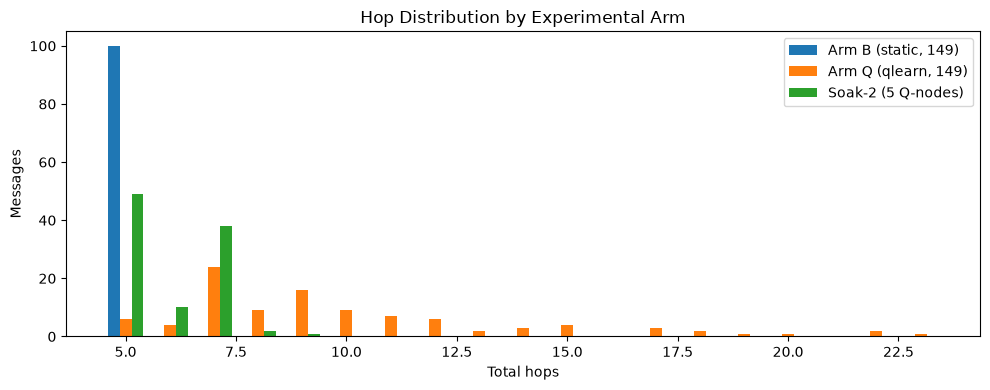

In [4]:
# Cell 4 — Hop distribution comparison (README figure)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
labels = list(results.keys())
all_hops = sorted({h for r in results.values() for h in r['hop_counts']})
width = 0.27
for i, lab in enumerate(labels):
    ys = [results[lab]['hop_counts'].get(h, 0) for h in all_hops]
    ax.bar([h + (i-1)*width for h in all_hops], ys, width=width, label=lab)
ax.set_xlabel('Total hops'); ax.set_ylabel('Messages')
ax.set_title('Hop Distribution by Experimental Arm')
ax.legend(); fig.tight_layout(); plt.show()

In [5]:
# Cell 5 — First-hop distribution & entropy from the implant log (node 74 / CTID 181)
# Parses '[Q] dest=... chose=N (explore|exploit)' decision lines.
def parse_decisions(log_path):
    pat = re.compile(r'\[Q\] dest=(\d+) chose=(\d+) \((explore|exploit)\) eps=([\d.]+)')
    decisions = []
    for line in Path(log_path).read_text(errors='replace').splitlines():
        m = pat.search(line)
        if m:
            decisions.append({'dest': int(m.group(1)), 'choice': int(m.group(2)),
                              'action': m.group(3), 'eps': float(m.group(4)),
                              'ts': line[:23]})
    return decisions

dec = parse_decisions(DATA/'logs'/'soak2-log-181.txt')
fh = Counter(d['choice'] for d in dec)
print(f'Soak-2 implant decisions: {len(dec)}')
print('First-hop distribution:', dict(fh.most_common()))
print(f'Top share: {max(fh.values())/len(dec):.0%} (criterion <= 70%: '
      f"{'PASS' if max(fh.values())/len(dec) <= 0.70 else 'FAIL'})")
print(f'First-hop entropy: {entropy(fh.values()):.2f} bits (ceiling log2(6)=2.585)')
explore = sum(1 for d in dec if d['action'] == 'explore')
print(f'Explore rate: {explore}/{len(dec)} = {explore/len(dec):.0%}')
eps_vals = [d['eps'] for d in dec]
print(f'eps trajectory: start {eps_vals[0]:.2f} -> end {eps_vals[-1]:.2f}')
# NOTE: log must be pre-rotation (single run). If multiple runs stacked, subtract counts first.

Soak-2 implant decisions: 100
First-hop distribution: {59: 76, 73: 10, 89: 4, 75: 4, 69: 3, 79: 3}
Top share: 76% (criterion <= 70%: FAIL)
First-hop entropy: 1.31 bits (ceiling log2(6)=2.585)
Explore rate: 22/100 = 22%
eps trajectory: start 0.30 -> end 0.18


In [6]:
# Cell 6 — Q-table drift: warm start vs post-run
PRISTINE_74 = {75: -0.06, 73: -0.05, 79: -0.06, 69: -0.06, 89: -0.05, 59: -0.04}

def load_qtable(path):
    d = json.loads(Path(path).read_text())
    flat = {}
    for dest, entry in d['table'].items():
        for nbr, v in entry.items():
            flat[int(nbr.split('_')[1])] = v
    return {'node_id': d['node_id'], 'epsilon': d['epsilon'], 'q': flat}

qt74 = load_qtable(DATA/'soak2-qtables'/'soak2-qtable-node74.json')
print(f"node 74 post-soak epsilon={qt74['epsilon']}")
print('neighbor | pristine | post-soak |   delta')
moved = False
for nbr in sorted(PRISTINE_74):
    pv, qv = PRISTINE_74[nbr], qt74['q'][nbr]
    flag = '' if abs(pv - qv) < 1e-9 else '  <- MOVED'
    moved = moved or bool(flag)
    print(f'{nbr:8d} | {pv:8.4f} | {qv:9.4f} | {qv-pv:+.5f}{flag}')
print(f'\nVerdict: {"LEARNING CONFIRMED (table moved from warm start)" if moved else "epsilon-dynamics only (table unchanged)"}')

node 74 post-soak epsilon=0.1817
neighbor | pristine | post-soak |   delta
      59 |  -0.0400 |   -0.0427 | -0.00267  <- MOVED
      69 |  -0.0600 |   -0.0600 | +0.00000
      73 |  -0.0500 |   -0.0529 | -0.00286  <- MOVED
      75 |  -0.0600 |   -0.0600 | +0.00000
      79 |  -0.0600 |   -0.0600 | +0.00000
      89 |  -0.0500 |   -0.0534 | -0.00342  <- MOVED

Verdict: LEARNING CONFIRMED (table moved from warm start)


In [7]:
# Cell 7 — INTERDICTION HARNESS (stub — fill in when harness artifacts exist)
# Expected artifact format per scenario: data/interdiction/<scenario>-response-stream.txt
# Metrics to compute per scenario:
#   - delivery rate (vs message index: recovery curve, messages-to-recovery)
#   - hop distribution + path-length entropy
#   - [Q-update] r=-1.000 lines per node = blame-diffusion trace
# Known failure semantics (code-verified):
#   - No in-flight reroute; failures penalize UPSTREAM hop, not dead-adjacent node.
#   - Prediction: partial recovery plateau, dead-adjacent black holes.
print('Interdiction analysis pending harness execution.')

Interdiction analysis pending harness execution.


## Section 8 — Routing Dynamics Simulator
**This is a model, not the fleet.** It reproduces the qualitative dynamics (diversity under exploration, blame-diffusion recovery, dead-adjacent black holes) on the same circulant topology and update rule, but NOT the measured hop counts — those come from the real daemon above.

In [8]:
# Cell 8 — Reduced simulator: circulant topology + Q-routing + kills
import random

class Sim:
    def __init__(self, n_nodes=149, chords=(1, 5, 15), dest=148, eps=0.3,
                 eps_decay=0.995, eps_floor=0.05, alpha=0.1, penalty=0.01,
                 max_hops=64, seed=None):
        self.rng = random.Random(seed)
        self.n, self.dest, self.eps = n_nodes, dest, eps
        self.eps_decay, self.eps_floor, self.alpha = eps_decay, eps_floor, alpha
        self.penalty, self.max_hops = penalty, max_hops
        self.neighbors = {
            i: ({(i + c) % n_nodes for c in chords}
            | {(i - c) % n_nodes for c in chords})
            for i in range(n_nodes)
        }
        cdist = lambda a, b: min((a-b) % n_nodes, (b-a) % n_nodes)
        # static routing + warm start on ideal path lengths (analytic)
        self.static_next = {i: min(self.neighbors[i], key=lambda nb: cdist(nb, dest))
                            for i in range(n_nodes)}
        self.q = {i: {} for i in range(n_nodes)}
        for i in range(n_nodes):
            for nb in self.neighbors[i]:
                self.q[i][nb] = -penalty * (cdist(nb, dest) + 1)  # warm start
        self.dead = set()

    def choose(self, node, visited, mode):
        cands = [nb for nb in sorted(self.neighbors[node]) if nb not in visited]
        if not cands:
            cands = sorted(self.neighbors[node])
        if mode == 'static':
            d = self.dest
            return min(cands, key=lambda nb: min((nb-d) % self.n, (d-nb) % self.n))
        if self.rng.random() < self.eps:
            choice = self.rng.choice(cands)
        else:
            best = max(self.q[node][nb] for nb in cands)
            choice = self.rng.choice([nb for nb in cands if self.q[node][nb] == best])
        self.eps = max(self.eps_floor, self.eps * self.eps_decay)
        return choice

    def send(self, src=74, mode='qlearn'):
        """One message. Returns (status, hops). Matches daemon: no in-flight reroute;
        ROUTE_FAILED propagates upstream; blame lands on hop before the failure."""
        path, node = [src], src
        while node != self.dest:
            if len(path) >= self.max_hops:
                return 'MAX_HOPS', path
            nxt = self.choose(node, set(path), mode)
            if nxt in self.dead:
                # failure attributed UPSTREAM (daemon behavior: connect error ->
                # RouteError at current node, caller penalizes its own choice)
                prev = path[-2] if len(path) >= 2 else None
                blamed = path[-2] if prev is not None else node
                if mode == 'qlearn' and blamed != node and blamed in self.q:
                    self.q[blamed][node] += self.alpha * (-1.0 - self.q[blamed][node])
                elif mode == 'qlearn' and node in self.q:
                    self.q[node][nxt] += self.alpha * (-1.0 - self.q[node][nxt])
                return 'ROUTE_FAILED', path
            path.append(nxt)
            node = nxt
        if mode == 'qlearn':
            total = len(path) - 1
            for pos, nd in enumerate(path[:-1], start=1):
                if path[pos] not in self.dead:
                    r = -self.penalty * max(total - pos, 0)
                    self.q[nd][path[pos]] += self.alpha * (r - self.q[nd][path[pos]])
        return 'delivered', path

    def run(self, msgs=100, src=74, mode='qlearn'):
        return [self.send(src, mode) for _ in range(msgs)]

# Baseline sanity check: static mode -> constant shortest path
sim = Sim(seed=42)
static_runs = sim.run(mode='static')
hops = [len(p)-1 for s, p in static_runs if s == 'delivered']
print(f'Sim static: {sum(1 for s,_ in static_runs if s=="delivered")}/{len(static_runs)} '
      f'delivered, hops={sorted(set(hops))}')
# Q mode at eps=0.3 -> diversity inflation (compare qualitatively to Arm Q)
sim = Sim(seed=42)
q_runs = sim.run(mode='qlearn')
qh = [len(p)-1 for s, p in q_runs if s == 'delivered']
print(f'Sim qlearn: {len(qh)}/100 delivered, mean hops={sum(qh)/len(qh):.2f}, '
      f'entropy={entropy(Counter(qh).values()):.2f} bits')

Sim static: 100/100 delivered, hops=[6]
Sim qlearn: 100/100 delivered, mean hops=6.91, entropy=1.40 bits


In [9]:
# Cell 9 — Simulated interdiction: chokepoint scenario (egress neighbors)
sim = Sim(seed=7)
pre = [s for s, _ in sim.run(50, mode='qlearn') if s == 'delivered']
print(f'Pre-kill delivery: {len(pre)}/50')
choke = sim.neighbors[sim.dest]  # kill egress's 6 neighbors (never egress itself)
sim.dead |= choke
post = [s for s, _ in sim.run(200, mode='qlearn') if s == 'delivered']
print(f'Chokepoint kill (6 egress-neighbors dead): delivery {len(post)}/200 over 200 msgs')
# Watch the recovery curve in 20-msg windows:
runs = [sim.send(mode='qlearn') for _ in range(200)]
for w in range(0, 200, 40):
    win = runs[w:w+40]
    ok = sum(1 for s, _ in win if s == 'delivered')
    print(f'  msgs {w:3d}-{w+39}: {ok}/40 delivered')
# NOTE: killing ALL egress neighbors makes delivery impossible (egress unreachable)
# — this is the SPOF result. Partial chokepoint = kill a subset; edit choke.

Pre-kill delivery: 50/50
Chokepoint kill (6 egress-neighbors dead): delivery 0/200 over 200 msgs
  msgs   0-39: 0/40 delivered
  msgs  40-79: 0/40 delivered
  msgs  80-119: 0/40 delivered
  msgs 120-159: 0/40 delivered
  msgs 160-199: 0/40 delivered
